
# BME 574 — companion notebook
## Diffusion models: a first implementation

A diffusion model in about a hundred lines. We build the forward process, train a small
denoiser on MNIST, and sample from it — the same walkthrough shown in the lecture,
written out in full. Then we load a model we trained properly, so you can see what the
same idea produces once the four fixes from the last slide are in.

Notation follows **Ho, Jain and Abbeel (2020)**, *Denoising Diffusion Probabilistic
Models*.

| section | what it does |
|---|---|
| 1 | the forward process: add noise on a fixed schedule |
| 2 | the model, and the one-line training objective |
| 3 | the sampler |
| 4 | what the walkthrough produces |
| 5 | the same idea, done properly |
| 6 | exercises |

**Budget.** About five minutes of CPU in total.

**What you need.** `torch`, `torchvision`, `numpy`, `matplotlib`, and the file
`long_ep080.pt` next to this notebook.

In [1]:
import math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision

torch.set_num_threads(4)          # raise this if your machine has more cores
torch.manual_seed(0); np.random.seed(0)

def mnist(n_train=12000):
    tr = torchvision.datasets.MNIST('data', train=True,  download=True)
    te = torchvision.datasets.MNIST('data', train=False, download=True)
    X  = (tr.data[:n_train].float()/255.)*2 - 1      # images live in [-1, 1]
    Xt = (te.data.float()/255.)*2 - 1
    return X.unsqueeze(1), Xt.unsqueeze(1)

X, Xt = mnist()
print(X.shape, 'pixels in [%.0f, %.0f]' % (X.min(), X.max()))

def show(rows, scale=0.75):
    "rows: list of (label, array of images)"
    fig, axes = plt.subplots(len(rows), 1, figsize=(9, scale*len(rows)))
    for ax, (lab, im) in zip(np.atleast_1d(axes), rows):
        im = np.clip(np.asarray(im), -1, 1)
        ax.imshow(np.concatenate(list(im), 1), cmap='gray', vmin=-1, vmax=1,
                  interpolation='nearest')
        ax.set_title(lab, fontsize=9, loc='left'); ax.axis('off')
    plt.tight_layout(); plt.show()

torch.Size([12000, 1, 28, 28]) pixels in [-1, 1]



---
## 1. The forward process

Add a little Gaussian noise, $T$ times:

$$q(\mathbf{x}_t \mid \mathbf{x}_{t-1}) = \mathcal{N}\!\left(\mathbf{x}_t;\;
\sqrt{1-\beta_t}\,\mathbf{x}_{t-1},\; \beta_t\mathbf{I}\right) \qquad\text{(Ho eq. 2)}$$

Nothing in this is learned — $\beta_t$ is a schedule you choose. The useful consequence
is that you can jump straight to any $t$:

$$\mathbf{x}_t = \sqrt{\bar\alpha_t}\,\mathbf{x}_0 + \sqrt{1-\bar\alpha_t}\,
\boldsymbol{\epsilon}, \qquad \alpha_t = 1-\beta_t, \quad
\bar\alpha_t = \prod_{s\le t}\alpha_s \qquad\text{(Ho eq. 4)}$$

So $\sqrt{\bar\alpha_t}$ is the fraction of the original image still present at step $t$.

In [2]:
class Schedule:
    def __init__(self, beta):
        self.beta        = beta
        self.alpha       = 1.0 - beta
        self.abar        = torch.cumprod(self.alpha, 0)
        self.sqrt_abar   = self.abar.sqrt()
        self.sqrt_1mabar = (1 - self.abar).sqrt()
        self.T           = len(beta)
    def q_sample(self, x0, t, noise):                   # eq. 4
        a = self.sqrt_abar[t].view(-1,1,1,1)
        b = self.sqrt_1mabar[t].view(-1,1,1,1)
        return a*x0 + b*noise

T   = 200
sch = Schedule(torch.linspace(1e-4, 0.02, T))           # the walkthrough's schedule
print('after %d steps, %.0f%% of the image is left' % (T, 100*sch.sqrt_abar[-1]))

after 200 steps, 36% of the image is left


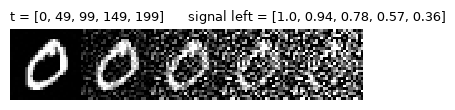

In [3]:
x0  = X[1:2]
g   = torch.Generator().manual_seed(4)
eps = torch.randn(x0.shape, generator=g)
ts  = [0, 49, 99, 149, 199]
show([('t = %s      signal left = %s'
       % (ts, [round(float(sch.sqrt_abar[t]), 2) for t in ts]),
       [sch.q_sample(x0, torch.tensor([t]), eps)[0,0].numpy() for t in ts])],
     scale=1.2)


**Look at the last panel.** You can still make out the digit — this schedule stops while
36% of the image is still there. Hold that thought until section 5.


---
## 2. The model and the objective

The network is handed a noisy image and the step it came from, and asked which noise was
added:

$$L_{\mathrm{simple}} = \mathbb{E}_{t,\mathbf{x}_0,\boldsymbol{\epsilon}}
\left\| \boldsymbol{\epsilon} - \boldsymbol{\epsilon}_\theta\!\left(
\sqrt{\bar\alpha_t}\mathbf{x}_0 + \sqrt{1-\bar\alpha_t}\boldsymbol{\epsilon},\; t
\right)\right\|^2 \qquad\text{(Ho eq. 14)}$$

A mean squared error. That is the entire training objective — no adversary, no sampling
loop, no second network.

The architecture below is the one from the walkthrough: three $3\times3$ convolutions.

In [4]:
class SimpleModel(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ch, 3, padding=1), nn.ReLU(),
            nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(),
            nn.Conv2d(ch, 1, 3, padding=1))
    def forward(self, x, t):
        return self.net(x)

def train(model, X, sch, epochs, seed=0, bs=128, lr=1e-3):
    "Ho et al. algorithm 1."
    torch.manual_seed(seed)
    opt, g = torch.optim.Adam(model.parameters(), lr=lr), torch.Generator().manual_seed(seed)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        perm, tot, n = torch.randperm(len(X), generator=g), 0.0, 0
        model.train()
        for i in range(0, len(X), bs):
            x0    = X[perm[i:i+bs]]
            t     = torch.randint(0, sch.T, (len(x0),), generator=g)
            noise = torch.randn(x0.shape, generator=g)
            loss  = F.mse_loss(model(sch.q_sample(x0, t, noise), t), noise)   # eq. 14
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(x0); n += len(x0)
        hist.append(tot/n)
        print('  epoch %2d/%d   L_simple %.4f   (%.0f s)'
              % (ep+1, epochs, hist[-1], time.time()-t0))
    model.eval(); return hist

print('parameters:', sum(p.numel() for p in SimpleModel().parameters()))

parameters: 9857


In [5]:
# about one minute
m = SimpleModel()
h = train(m, X, sch, epochs=5)

  epoch  1/5   L_simple 0.3526   (9 s)
  epoch  2/5   L_simple 0.2159   (17 s)
  epoch  3/5   L_simple 0.1793   (26 s)
  epoch  4/5   L_simple 0.1601   (34 s)
  epoch  5/5   L_simple 0.1458   (43 s)



---
## 3. The sampler

Start from pure noise and walk the chain backwards, one step at a time
(Ho et al. algorithm 2):

$$\mathbf{x}_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(\mathbf{x}_t -
\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\boldsymbol{\epsilon}_\theta(\mathbf{x}_t,t)\right)
+ \sigma_t\mathbf{z}$$

The version below is written so that the clean image the model is *implying* —
$\hat{\mathbf{x}}_0$, obtained by solving eq. 4 for $\mathbf{x}_0$ — is visible on its own
line. It is algebraically the same sampler, and it lets us switch on one safeguard in
section 5.

In [6]:
@torch.no_grad()
def sample(model, sch, n=14, seed=0, clip=False, keep=None, bs=64):
    torch.manual_seed(seed)
    x, frames = torch.randn(n,1,28,28), {}
    for i in reversed(range(sch.T)):
        t   = torch.full((bs,), i, dtype=torch.long)
        eps = torch.cat([model(x[j:j+bs], t[:len(x[j:j+bs])]) for j in range(0,n,bs)])
        a, ab, b = sch.alpha[i], sch.abar[i], sch.beta[i]
        x0 = (x - (1-ab).sqrt()*eps) / ab.sqrt()        # the implied clean image
        if clip:
            x0 = x0.clamp(-1, 1)
        ab_prev = sch.abar[i-1] if i > 0 else torch.tensor(1.0)
        mean = (ab_prev.sqrt()*b/(1-ab))*x0 + (a.sqrt()*(1-ab_prev)/(1-ab))*x
        x = mean + (b*(1-ab_prev)/(1-ab)).sqrt()*torch.randn_like(x) if i > 0 else mean
        if keep and i in keep:
            frames[i] = x.clone()
    return x, frames


---
## 4. What the walkthrough produces

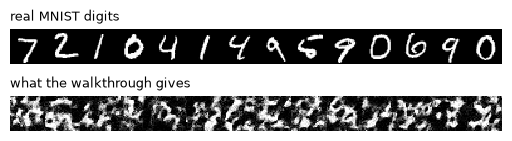

pixel range of the samples: [-1.7, 1.6]   (images live in [-1, 1])


In [7]:
xs, _ = sample(m, sch, n=14, seed=0)
show([('real MNIST digits',           Xt[:14,0].numpy()),
      ('what the walkthrough gives',  xs[:,0].numpy())])
print('pixel range of the samples: [%.1f, %.1f]   (images live in [-1, 1])'
      % (xs.min(), xs.max()))


Texture, not digits — and the training loss fell the whole way. This is a faithful run of
a reasonable-looking first attempt, which is the most common kind of machine learning
result.

**Before reading on, write down your guess at which of these is to blame:**

1. the network is too small,
2. `forward(self, x, t)` never uses `t`,
3. the chain stops while a third of the image is still there,
4. the sampler does something unsafe,
5. five epochs is not enough.

The answer in the lecture is *all five*, and the surprise is their order of importance.


---
## 5. The same idea, done properly

The model loaded below is the same objective, the same sampler and the same data, with
four changes:

| | change |
|---|---|
| 1 | the timestep is embedded and fed into every layer |
| 2 | a cosine schedule with $T = 400$, which ends at $\sqrt{\bar\alpha_T} = 0.0001$ instead of 0.36 |
| 3 | $\hat{\mathbf{x}}_0$ is clamped into $[-1,+1]$ at every reverse step (`clip=True` below) |
| 4 | a small U-Net, 341,041 parameters, trained for 12,560 gradient steps |

Changes 2 and 3 are not changes to the model at all.

In [8]:
def cosine_beta(T, s=0.008):
    "Nichol and Dhariwal (2021), eq. 17 — a schedule that actually reaches noise."
    x  = torch.linspace(0, T, T+1)
    f  = torch.cos(((x/T) + s)/(1+s) * math.pi/2)**2
    ab = f/f[0]
    return (1 - ab[1:]/ab[:-1]).clamp(1e-8, 0.999)

cos400 = Schedule(cosine_beta(400))
print('walkthrough schedule ends at %.4f' % sch.sqrt_abar[-1])
print('cosine schedule ends at      %.4f' % cos400.sqrt_abar[-1])

walkthrough schedule ends at 0.3636
cosine schedule ends at      0.0001


In [10]:
# the U-Net the checkpoint was trained with
def timestep_embedding(t, dim):
    half  = dim//2
    freqs = torch.exp(-math.log(10000)*torch.arange(half, dtype=torch.float32)/half)
    a = t.float().view(-1,1)*freqs.view(1,-1)
    return torch.cat([torch.sin(a), torch.cos(a)], -1)

class Block(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(cin,cout,3,padding=1), nn.Conv2d(cout,cout,3,padding=1)
        self.t  = nn.Linear(tdim, cout)
        self.n1, self.n2 = nn.GroupNorm(8,cout), nn.GroupNorm(8,cout)
        self.skip = nn.Conv2d(cin,cout,1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x)))
        h = h + self.t(e).unsqueeze(-1).unsqueeze(-1)       # <- the timestep, fix 1
        h = F.silu(self.n2(self.c2(h)))
        return h + self.skip(x)

class UNet(nn.Module):
    def __init__(self, ch=(24,48,64), tdim=64):
        super().__init__()
        self.tdim = tdim
        self.temb = nn.Sequential(nn.Linear(tdim,tdim), nn.SiLU(), nn.Linear(tdim,tdim))
        c0, c1, c2 = ch
        self.inp = nn.Conv2d(1, c0, 3, padding=1)
        self.d1, self.d2, self.d3 = Block(c0,c0,tdim), Block(c0,c1,tdim), Block(c1,c2,tdim)
        self.mid = Block(c2,c2,tdim)
        self.u3, self.u2, self.u1 = Block(c2+c2,c1,tdim), Block(c1+c1,c0,tdim), Block(c0+c0,c0,tdim)
        self.out, self.pool = nn.Conv2d(c0,1,3,padding=1), nn.AvgPool2d(2)
    def forward(self, x, t):
        e  = self.temb(timestep_embedding(t, self.tdim))
        h0 = self.inp(x); h1 = self.d1(h0, e)
        h2 = self.d2(self.pool(h1), e); h3 = self.d3(self.pool(h2), e)
        u  = self.u3(torch.cat([self.mid(h3, e), h3], 1), e)
        u  = self.u2(torch.cat([F.interpolate(u, size=h2.shape[-2:]), h2], 1), e)
        u  = self.u1(torch.cat([F.interpolate(u, size=h1.shape[-2:]), h1], 1), e)
        return self.out(u)

ck = torch.load('long_ep080.pt', map_location='cpu')
big = UNet(); big.load_state_dict(ck['sd']); big.eval()
print('%s parameters, %s gradient steps, final L_simple %.4f'
      % (f"{sum(p.numel() for p in big.parameters()):,}", f"{ck['steps']:,}",
         ck['hist'][-1]))

341,041 parameters, 12,560 gradient steps, final L_simple 0.0387


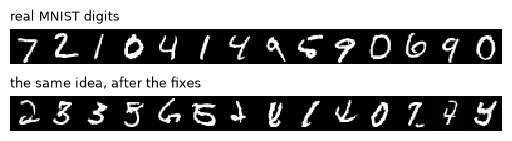

In [11]:
# about one minute
xs_big, _ = sample(big, cos400, n=14, seed=0, clip=True)
show([('real MNIST digits',              Xt[:14,0].numpy()),
      ('the same idea, after the fixes', xs_big[:,0].numpy())])

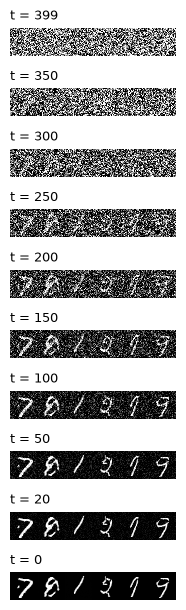

In [12]:
# watch one chain run backwards
keep = [399, 350, 300, 250, 200, 150, 100, 50, 20, 0]
_, frames = sample(big, cos400, n=6, seed=5, clip=True, keep=set(keep))
show([('t = %d' % t, frames[t][:6,0].numpy()) for t in keep], scale=0.62)


The global shape of each digit is settled early, while the image still looks like noise.
The last hundred steps are detail.


---
## Exercises

**1.** In section 4 the samples left the range $[-1,+1]$. Sample from the trained U-Net
with `clip=False` and print `x.min()` and `x.max()` every fifty steps. Where in the chain
does it escape, and why there? (Hint: look at `cos400.sqrt_abar[-20:]`, and at what
$\hat{\mathbf{x}}_0$ divides by.)

**2.** Train `SimpleModel` again with everything the same except $T = 1000$ instead of
200. Does it help? Write down your prediction first.

**3.** Modify `SimpleModel` so that it actually uses `t`: pass `t.float()/T` through a
small `nn.Linear` and add the result to the feature maps after each convolution. Retrain
for five epochs and compare. Is the improvement as large as you expected?

**4.** *Looking ahead.* Sampling cost is $T$ forward passes per image. Skim the abstract
of Song, Meng and Ermon (2021), *Denoising Diffusion Implicit Models*, and describe in two
sentences how they cut that cost without retraining.

---

### Reading

* Ho, Jain and Abbeel (2020), *Denoising Diffusion Probabilistic Models* — equations (1),
  (2), (4) and (14), and algorithms 1 and 2 are everything in this notebook.
* Nichol and Dhariwal (2021), *Improved Denoising Diffusion Probabilistic Models* —
  section 3 explains why the linear schedule wastes steps.